# 07 · Previsão pelo Elo e calibração (D21)

A previsão do site é a probabilidade da fórmula do Elo, sem modelo treinado (o modelo fica para
depois do D30, com o Elo como baseline a superar). Este notebook mede se a probabilidade é
**calibrada** na janela: quando o Elo diz 70%, o favorito vence ~70% das vezes?

- **Log loss** e **Brier** com IC por bootstrap, contra a moeda (0,693 e 0,25);
- **curva de calibração** por faixa de probabilidade, com IC de Wilson;
- por tier.

Acurácia fica de fora de propósito: ela premia acertar o lado, não a probabilidade.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

In [2]:
cal = A.calibration(con)
pd.DataFrame([
    {"recorte": k, "partidas": v["n"], "log loss": v["log_loss"].text(4),
     "Brier": v["brier"].text(4), "moeda (log loss)": round(v["coin_log_loss"], 4)}
    for k, v in cal.items()
])

,recorte,partidas,log loss,Brier,moeda (log loss)
0,all,2658,"0,6609 (IC 95% 0,6505–0,6712)","0,2329 (IC 95% 0,2279–0,2375)",0.693
1,vcl,2040,"0,6542 (IC 95% 0,6434–0,6650)","0,2296 (IC 95% 0,2245–0,2347)",0.693
2,vct,618,"0,6830 (IC 95% 0,6566–0,7094)","0,2437 (IC 95% 0,2316–0,2556)",0.693


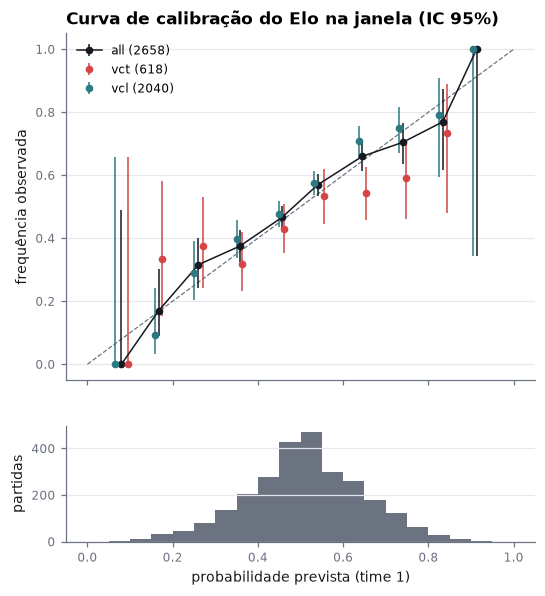

In [3]:
fig, (ax, axh) = plt.subplots(2, 1, figsize=(5.5, 6), height_ratios=[3, 1], sharex=True)
ax.plot([0, 1], [0, 1], color=P.MUTED, lw=0.8, ls="--")
for key, color, offset in [("all", P.INK, 0.0), ("vct", P.ATTACK, 0.008), ("vcl", P.DEFENSE, -0.008)]:
    c = pd.DataFrame(cal[key]["curve"])
    obs = pd.json_normalize(c.observed)
    ax.errorbar(c.predicted + offset, obs.value, yerr=[obs.value - obs.low, obs.high - obs.value],
                fmt="o-" if key == "all" else "o", ms=4, lw=1 if key == "all" else 0,
                elinewidth=1, color=color, label=f"{key} ({cal[key]['n']})")
ax.set_ylabel("frequência observada")
ax.set_title("Curva de calibração do Elo na janela (IC 95%)")
ax.legend(loc="upper left")
probs = A.table(con, "mart_elo_calibration").team1_win_probability
axh.hist(probs, bins=20, range=(0, 1), color=P.MUTED)
axh.set_xlabel("probabilidade prevista (time 1)")
axh.set_ylabel("partidas")
P.save(fig, "calibracao.png")
plt.show()

## Matriz de confrontos

O critério de pronto do D21: a matriz par a par dos times ativos na janela em Parquet
(`mart_matchups`, materialização `external` do dbt em `data/derived/matchups.parquet`). O
`site_artifacts` a lê para gerar `predictions/{id}.json`.

In [4]:
import os
derived = Path(os.environ.get("DERIVED_DIR", ROOT / "data" / "derived"))
matchups = pd.read_parquet(derived / "matchups.parquet")
ratings = A.ratings(con).set_index("team_id")
top2 = ratings[ratings.tier == "vct"].head(2)
a, b = top2.index
print(f"{len(matchups):,} confrontos, {matchups.team_id.nunique()} times; "
      f"{(derived / 'matchups.parquet').stat().st_size / 1e6:.1f} MB")
print(f"{ratings.loc[a, 'team_name']} × {ratings.loc[b, 'team_name']}: "
      f"{A.matchup(con, a, b):.1%} para o primeiro")
matchups.describe().round(3)

196,692 confrontos, 444 times; 1.6 MB
100 Thieves × Team Vitality: 56.7% para o primeiro


,rating,opponent_rating,win_probability
count,196692.000,196692.000,196692.000
mean,1397.448,1397.448,0.500
std,135.654,135.654,0.215
min,1139.107,1139.107,0.013
25%,1307.247,1307.247,0.368
50%,1348.667,1348.667,0.500
75%,1447.865,1447.865,0.632
max,1888.651,1888.651,0.987


## Conclusão

In [5]:
all_, vct, vcl = cal["all"], cal["vct"], cal["vcl"]
def vs_coin(c):
    return ("melhor que a moeda (IC abaixo de 0,693)" if c["log_loss"].high < c["coin_log_loss"]
            else "**indistinguível da moeda** (o IC inclui 0,693)")
display(Markdown(f"""
- Na janela ({all_['n']} séries), log loss **{all_['log_loss'].text(4)}** e Brier
  **{all_['brier'].text(4)}**: {vs_coin(all_)}.
- VCL ({vcl['n']}): {vcl['log_loss'].text(4)}, {vs_coin(vcl)}.
- VCT ({vct['n']}): {vct['log_loss'].text(4)}, {vs_coin(vct)}. No topo, os times são parecidos e o
  Elo só por resultado de série tem pouco a dizer; é a parte que um modelo pós-D30 precisa melhorar.
- A curva acompanha a diagonal dentro do IC nas faixas com amostra: o Elo não é confiante demais.
"""))


- Na janela (2658 séries), log loss **0,6609 (IC 95% 0,6505–0,6712)** e Brier
  **0,2329 (IC 95% 0,2279–0,2375)**: melhor que a moeda (IC abaixo de 0,693).
- VCL (2040): 0,6542 (IC 95% 0,6434–0,6650), melhor que a moeda (IC abaixo de 0,693).
- VCT (618): 0,6830 (IC 95% 0,6566–0,7094), **indistinguível da moeda** (o IC inclui 0,693). No topo, os times são parecidos e o
  Elo só por resultado de série tem pouco a dizer; é a parte que um modelo pós-D30 precisa melhorar.
- A curva acompanha a diagonal dentro do IC nas faixas com amostra: o Elo não é confiante demais.
